# Lab 4 — Cross-hedging jet fuel with heating oil futures

In [2]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

START, END = "2000-09-01", "2026-10-31"

### Q1 — Heating oil futures (`HO=F`)

In [3]:
ho = yf.download("HO=F", start=START, end=END, auto_adjust=False)["Close"]
ho = ho.squeeze().rename("HO")
print(ho.head()); print(ho.tail()); print("Obs:", len(ho))

[*********************100%***********************]  1 of 1 completed

Date
2000-09-01    0.9764
2000-09-05    0.9797
2000-09-06    0.9966
2000-09-07    1.0295
2000-09-08    0.9949
Name: HO, dtype: float64
Date
2026-10-26    4.9120
2026-10-27    4.7752
2026-10-28    4.8152
2026-10-29    4.7360
2026-10-30    4.7905
Name: HO, dtype: float64
Obs: 6570


### Q2 — Jet fuel spot (`DJFUELUSGULF`)

In [4]:
url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DJFUELUSGULF"
jf = pd.read_csv(url, index_col=0, parse_dates=True, na_values=".").squeeze().rename("JF")
print(jf.head()); print(jf.tail()); print("Obs:", len(jf))

observation_date
1990-04-02    0.550
1990-04-03    0.555
1990-04-04    0.560
1990-04-05    0.540
1990-04-06    0.536
Name: JF, dtype: float64
observation_date
2026-11-11    4.035
2026-11-12    4.062
2026-11-13    4.032
2026-11-16    3.794
2026-11-17    3.763
Name: JF, dtype: float64
Obs: 9557


### Q3 — Merge, returns, cumulative plot

Sample: 2000-09-12 to 2026-10-30 | n = 6093
                HO           JF
count  6093.000000  6093.000000
mean      0.000252     0.000233
std       0.024444     0.028795
min      -0.247536    -0.281038
25%      -0.011969    -0.013057
50%       0.000835     0.000526
75%       0.012740     0.013986
max       0.123572     0.326421
Correlation of daily returns: 0.8167


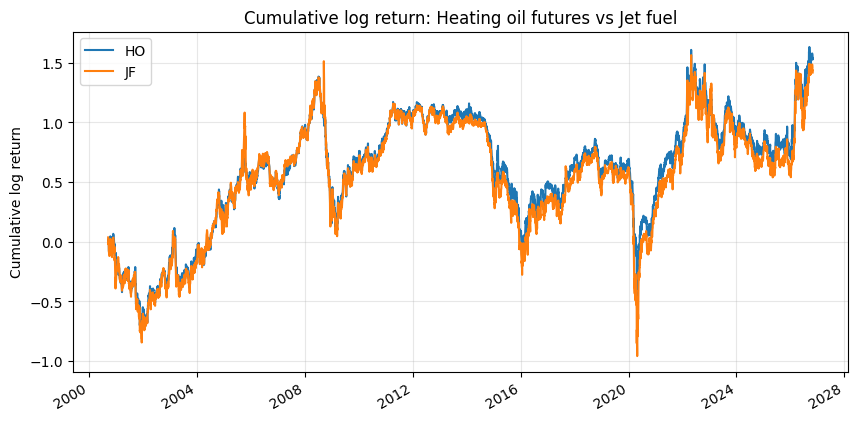

In [5]:
df = pd.concat([ho, jf], axis=1, join="inner").dropna()
df = df.loc[START:END]
df = df[(df > 0).all(axis=1)]          # guard against bad/zero prints before taking logs

ret = np.log(df).diff().dropna()
print("Sample:", ret.index.min().date(), "to", ret.index.max().date(), "| n =", len(ret))
print(ret.describe())
print("Correlation of daily returns:", round(ret.corr().iloc[0, 1], 4))

cum = ret.cumsum()
ax = cum.plot(figsize=(10, 5), title="Cumulative log return: Heating oil futures vs Jet fuel")
ax.set_ylabel("Cumulative log return"); ax.grid(alpha=0.3)
plt.show()

The two lines move almost together: the same run-up to 2008, the crash in late 2008, the 2014–16 slump, the COVID trough in 2020, and the 2022 spike. This is visual evidence that heating oil tracks jet fuel closely, which is the premise of the cross-hedge. The only time they really diverge is in 2020 when jet demand collapsed faster than other fuels and heating oil. That is the basis risk part of the airline's exposure that futures cannot remove.

### Q4 — Annual volatility

In [6]:
spy = yf.download("SPY", start=START, end=END, auto_adjust=True)["Close"].squeeze().rename("SPY")
df3 = pd.concat([df, spy], axis=1, join="inner").dropna()
ret3 = np.log(df3).diff().dropna()

vol_ann = ret3.std() * np.sqrt(252)
summary = pd.DataFrame({"Annual vol": vol_ann, "Multiple of SPY vol": vol_ann / vol_ann["SPY"]})
print(summary.round(4))

[*********************100%***********************]  1 of 1 completed

     Annual vol  Multiple of SPY vol
HO       0.3878               1.9608
JF       0.4571               2.3112
SPY      0.1978               1.0000


Both energy series are roughly 2x as volatile as SPY, and their vols should be close to each other. Energy prices react to supply shocks, inventories, weather and refinery outages, while SPY is a diversified basket of 500 firms. That volatility is why fuel is a major risk to airline earnings and why hedging matters.

### Q5 — Regression of jet fuel on heating oil futures

In [ ]:
x, y = ret["HO"].values, ret["JF"].values #extract the data for the regression
n = len(x) #number of observations
X = np.column_stack([np.ones(n), x]) #create the design matrix with a column of ones for the intercept
(alpha, beta), *_ = np.linalg.lstsq(X, y, rcond=None) #perform the linear regression using least squares to estimate alpha (intercept) and beta (slope)

residual = y - (alpha + beta * x) #residuals from the regression
sigma2 = residual @ residual / (n - 2) #matrix multiplication to get residual sum of squares
se_alpha, se_beta = np.sqrt(np.diag(sigma2 * np.linalg.inv(X.T @ X))) #standard errors of alpha and beta
r2 = 1 - (residual @ residual) / ((y - y.mean()) @ (y - y.mean())) #R-squared

reg = pd.DataFrame({"coeff": [alpha, beta], "std err": [se_alpha, se_beta], "t": [alpha / se_alpha, beta / se_beta]}, index=["alpha", "beta"]) #actual regression results in a DataFrame
print(reg.round(6)) #print the regression coefficients, their standard errors, and t-statistics rounded to 6 decimal places
print(f"\nR-squared = {r2:.4f} n = {n}") #print the R-squared value and the number of observations used in the regression
print(f"Check: rho^2 = {np.corrcoef(x,y)[0,1]**2:.4f} (equals R^2 in a one-regressor OLS)") #prints the square of the correlation coefficient between x and y, which should equal R^2 in a simple linear regression with one independent variable.

          coeff   std err           t
alpha -0.000010  0.000213   -0.047490
beta   0.962053  0.008710  110.448589

R-squared = 0.6670 n = 6093
Check: rho^2 = 0.6670 (equals R^2 in a one-regressor OLS)


### Q6 — Volatility of the hedged position vs N

### Q7 — How the two points relate to the regression